# [Lab 5-3] GAN (Generative Adversarial Network) 기반 MNIST 손글씨 숫자 생성 실습
---
이 노트북에서는 Generative Adversarial Network (GAN)를 구현하여 MNIST 손글씨 숫자를 생성합니다.

In [1]:
%matplotlib inline
import os
import logging
import platform
import numpy as np
import matplotlib.pyplot as plt
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import tensorflow as tf
from tensorflow.keras import layers

tf.get_logger().setLevel("ERROR")
logging.getLogger("tensorflow").setLevel(logging.ERROR)

if platform.system() == "Windows":
    plt.rc("font", family="Malgun Gothic")
elif platform.system() == "Darwin":
    plt.rc("font", family="AppleGothic")
else:
    plt.rc("font", family="NanumGothic")
plt.rcParams["axes.unicode_minus"] = False

tf.random.set_seed(42)
np.random.seed(42)

import sys
from pathlib import Path as _Path
_root = next(
    p for p in [_Path.cwd().resolve(), *_Path.cwd().resolve().parents]
    if (p / ".cursor" / "runtime_device.py").exists()
)
if str(_root / ".cursor") not in sys.path:
    sys.path.insert(0, str(_root / ".cursor"))
import runtime_device
runtime_device.configure_tensorflow(tf)
print("TensorFlow 버전:", tf.__version__)


OS: Darwin
학습 장치: MPS (Apple GPU) [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
배치된 장치: /job:localhost/replica:0/task:0/device:GPU:0
TensorFlow 버전: 2.17.1


## 1. 데이터 준비

In [2]:
(x_train, _), (_, _) = tf.keras.datasets.mnist.load_data()

x_train = (x_train.astype("float32") / 127.5) - 1.0
x_train = np.expand_dims(x_train, -1)

BUFFER_SIZE = 60000
BATCH_SIZE = 256

train_dataset = tf.data.Dataset.from_tensor_slices(x_train).shuffle(BUFFER_SIZE).batch(BATCH_SIZE)

## 2. Generator 정의

In [3]:
def make_generator_model():
    model = tf.keras.Sequential()
    model.add(layers.Input(shape=(100,)))
    model.add(layers.Dense(7*7*256, use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    model.add(layers.Reshape((7, 7, 256)))
    model.add(layers.Conv2DTranspose(128, (5,5), strides=(1,1), padding="same", use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    model.add(layers.Conv2DTranspose(64, (5,5), strides=(2,2), padding="same", use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    model.add(layers.Conv2DTranspose(1, (5,5), strides=(2,2), padding="same", use_bias=False, activation="tanh"))
    return model

generator = make_generator_model()
generator.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 7, 7, 128)      │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │         1,600 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,330,944 (8.89 MB)

 Trainable params: 2,305,472 (8.79 MB)

 Non-trainable params: 25,472 (99.50 KB)

## 3. Discriminator 정의

In [4]:
def make_discriminator_model():
    model = tf.keras.Sequential()
    model.add(layers.Input(shape=(28, 28, 1)))
    model.add(layers.Conv2D(64, (5,5), strides=(2,2), padding="same"))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))

    model.add(layers.Conv2D(128, (5,5), strides=(2,2), padding="same"))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))

    model.add(layers.Flatten())
    model.add(layers.Dense(1))
    return model

discriminator = make_discriminator_model()
discriminator.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

## 4. 손실 함수와 Optimizer

In [5]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

generator_optimizer = tf.keras.optimizers.Adam(1e-4)
discriminator_optimizer = tf.keras.optimizers.Adam(1e-4)

## 5. 학습 루프 정의

In [6]:
EPOCHS = 30
noise_dim = 100
num_examples_to_generate = 16

seed = tf.random.normal([num_examples_to_generate, noise_dim])

@tf.function
def train_step(images):
    bs = tf.shape(images)[0]
    noise = tf.random.normal([bs, noise_dim])
    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)

        real_output = discriminator(images, training=True)
        fake_output = discriminator(generated_images, training=True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

    return gen_loss, disc_loss

def train(dataset, epochs):
    for epoch in range(epochs):
        for image_batch in dataset:
            g_loss, d_loss = train_step(image_batch)
        print(f"Epoch {epoch+1}, Gen Loss: {g_loss:.4f}, Disc Loss: {d_loss:.4f}")

        generate_and_save_images(generator, epoch+1, seed)

def generate_and_save_images(model, epoch, test_input):
    predictions = model(test_input, training=False)
    fig = plt.figure(figsize=(4,4))

    for i in range(predictions.shape[0]):
        plt.subplot(4,4,i+1)
        plt.imshow(predictions[i,:,:,0]*127.5+127.5, cmap="gray")
        plt.axis("off")
    plt.suptitle(f"Epoch {epoch}")
    plt.show()

## 6. 모델 학습 실행

Epoch 1, Gen Loss: 0.8162, Disc Loss: 1.2066


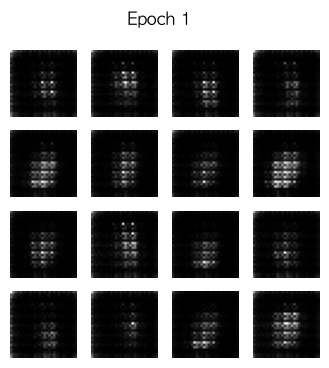

Epoch 2, Gen Loss: 0.7020, Disc Loss: 1.4135


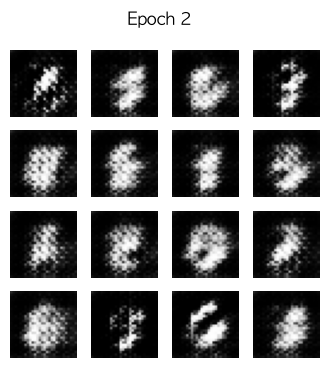

Epoch 3, Gen Loss: 0.7640, Disc Loss: 1.3210


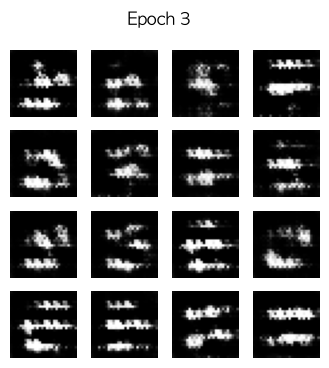

Epoch 4, Gen Loss: 0.8017, Disc Loss: 1.3263


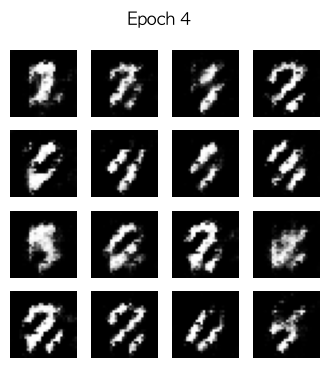

Epoch 5, Gen Loss: 0.7015, Disc Loss: 1.4717


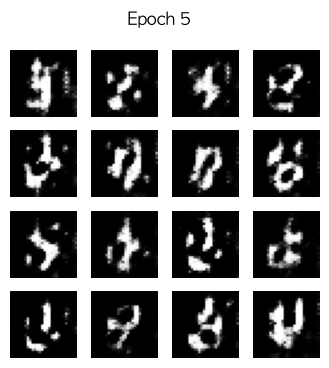

Epoch 6, Gen Loss: 0.7360, Disc Loss: 1.4439


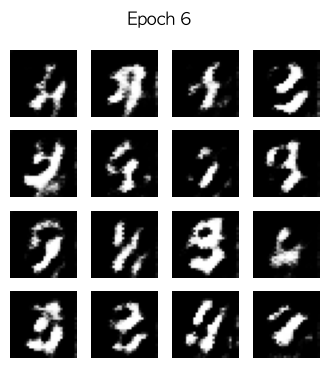

Epoch 7, Gen Loss: 0.7517, Disc Loss: 1.3374


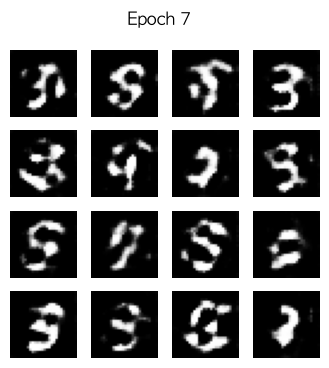

Epoch 8, Gen Loss: 0.8535, Disc Loss: 1.2402


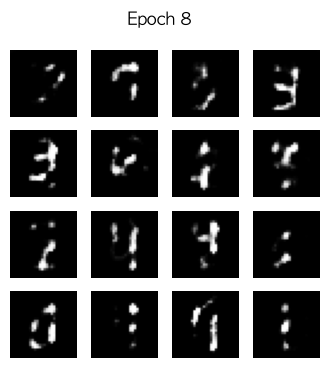

Epoch 9, Gen Loss: 0.8216, Disc Loss: 1.3453


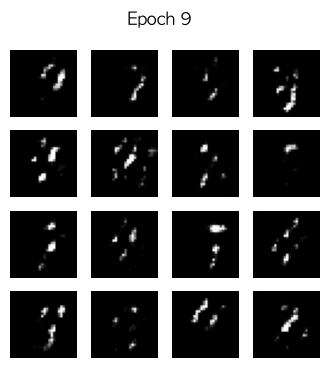

Epoch 10, Gen Loss: 0.8440, Disc Loss: 1.1251


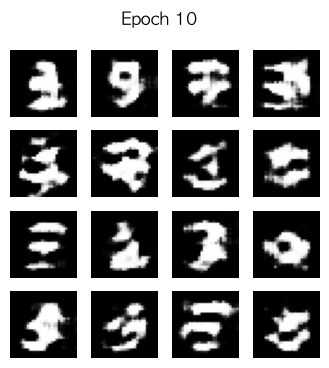

Epoch 11, Gen Loss: 0.8218, Disc Loss: 1.3295


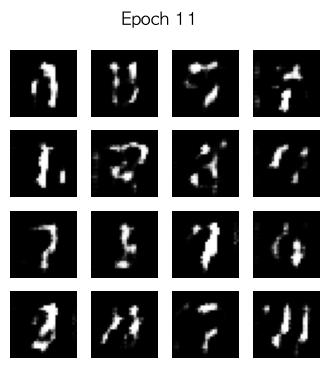

Epoch 12, Gen Loss: 0.8331, Disc Loss: 1.3524


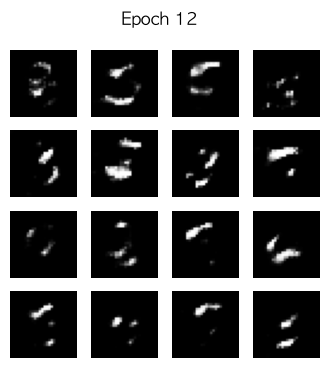

Epoch 13, Gen Loss: 0.7915, Disc Loss: 1.3042


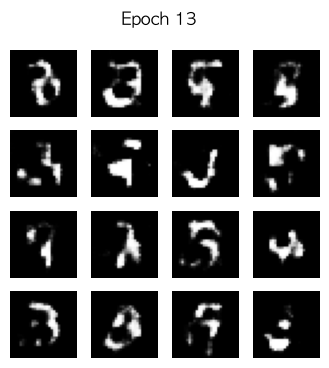

Epoch 14, Gen Loss: 0.7166, Disc Loss: 1.3102


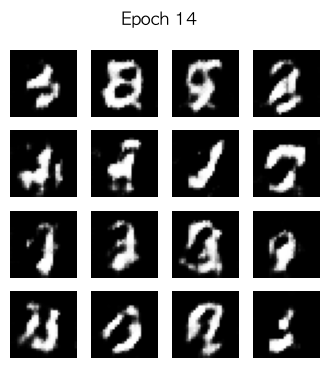

Epoch 15, Gen Loss: 0.8354, Disc Loss: 1.2909


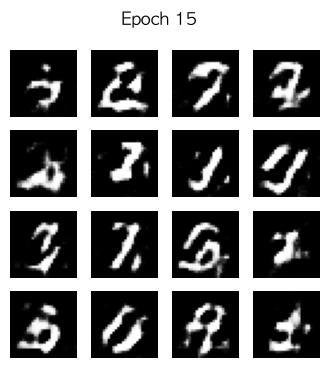

Epoch 16, Gen Loss: 0.8447, Disc Loss: 1.1886


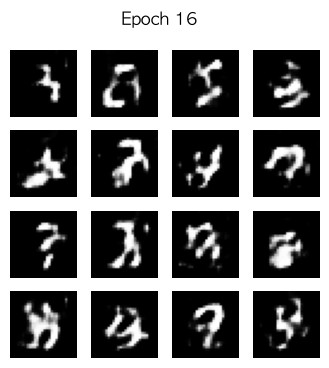

Epoch 17, Gen Loss: 0.7930, Disc Loss: 1.3172


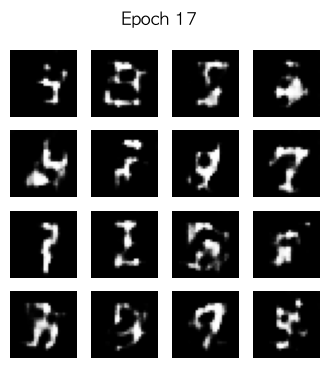

Epoch 18, Gen Loss: 0.8432, Disc Loss: 1.3037


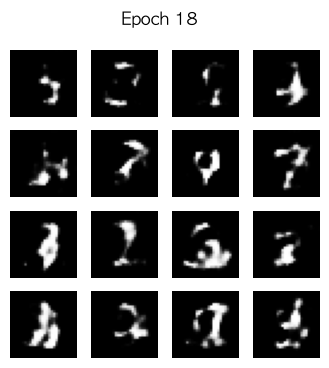

Epoch 19, Gen Loss: 0.8064, Disc Loss: 1.3409


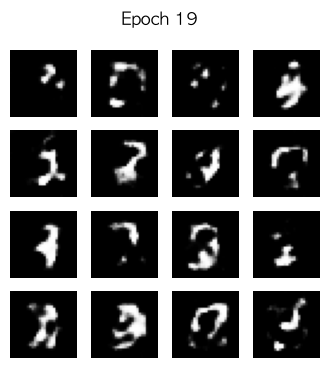

Epoch 20, Gen Loss: 0.7604, Disc Loss: 1.3332


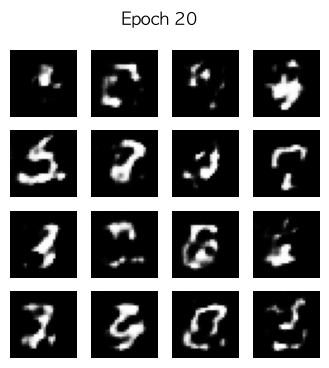

Epoch 21, Gen Loss: 0.7398, Disc Loss: 1.3820


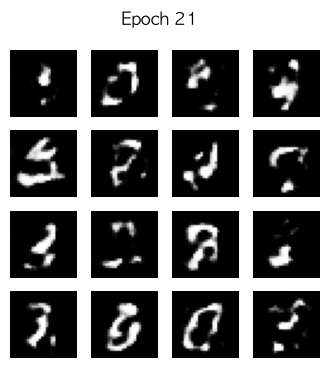

Epoch 22, Gen Loss: 0.7389, Disc Loss: 1.4013


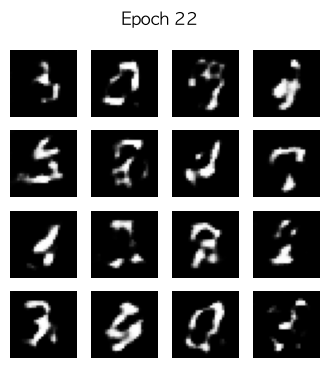

Epoch 23, Gen Loss: 0.7565, Disc Loss: 1.3010


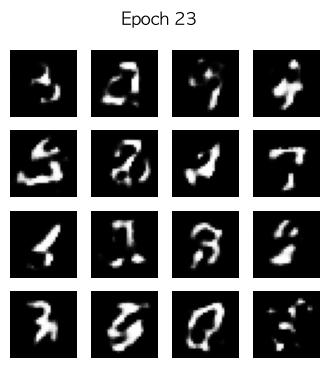

Epoch 24, Gen Loss: 0.7125, Disc Loss: 1.3875


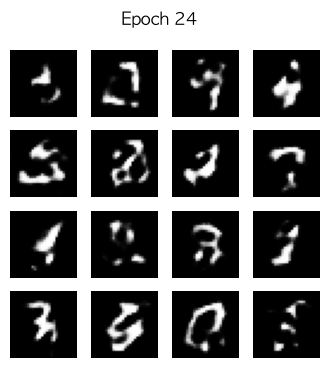

Epoch 25, Gen Loss: 0.7162, Disc Loss: 1.4272


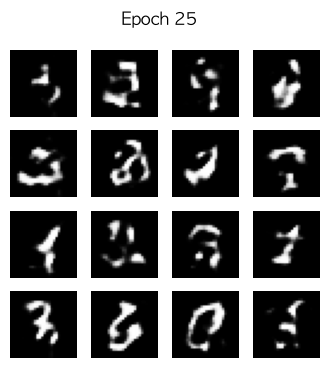

Epoch 26, Gen Loss: 0.7002, Disc Loss: 1.4099


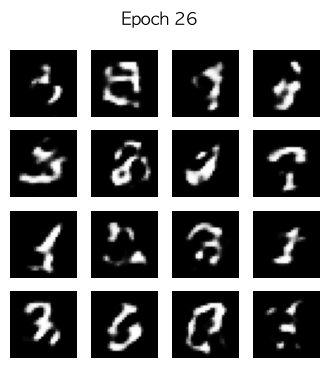

Epoch 27, Gen Loss: 0.7088, Disc Loss: 1.4000


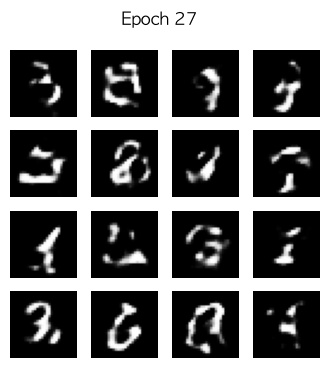

Epoch 28, Gen Loss: 0.7356, Disc Loss: 1.3880


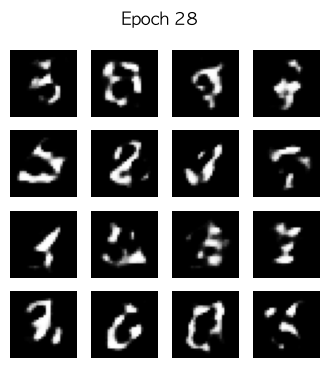

Epoch 29, Gen Loss: 0.8864, Disc Loss: 1.0487


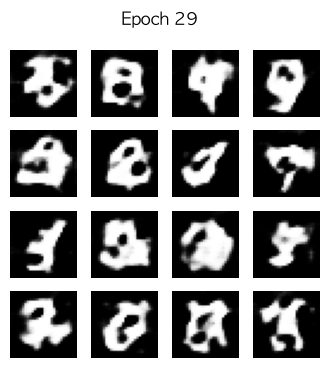

Epoch 30, Gen Loss: 0.8836, Disc Loss: 1.2036


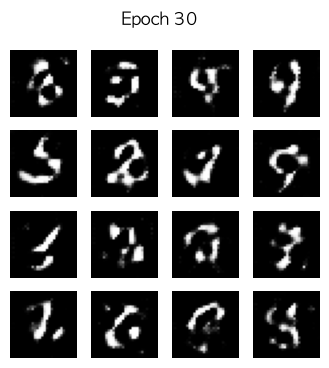

In [7]:
train(train_dataset, EPOCHS)

## 7. 최종 손글씨 생성

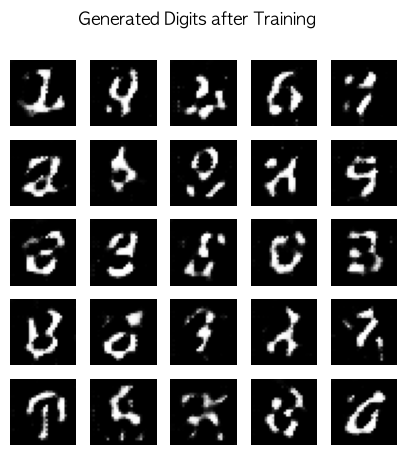

In [8]:
noise = tf.random.normal([25, noise_dim])
generated_images = generator(noise, training=False)

plt.figure(figsize=(5,5))
for i in range(generated_images.shape[0]):
    plt.subplot(5,5,i+1)
    plt.imshow(generated_images[i,:,:,0]*127.5+127.5, cmap="gray")
    plt.axis("off")
plt.suptitle("Generated Digits after Training")
plt.show()

### [생각해보기 - GAN의 적대적 학습]
1. Generator와 Discriminator는 각각 무엇을 학습하나요?
2. 둘을 서로 이기게 학습하면 왜 실제와 비슷한 이미지가 나오나요?


**나의 답변:**

1. Generator는 무작위 노이즈를 받아 가짜 손글씨를 만들고, Discriminator는 진짜와 가짜를 가려낸다.  
   따라서 생성자는 판별자를 속이는 쪽으로, 판별자는 더 잘 구분하는 쪽으로 서로 밀어붙인다.

2. 두 네트워크가 번갈아 이기려다 보면, 생성자가 만든 이미지가 진짜 데이터 분포에 가까워진다.  
   다만 한쪽이 너무 강해지면 학습이 흔들리거나 다양성이 줄어들 수 있어서, 균형을 유지하는 것이 중요하다.
